In [30]:
#libraries import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [31]:
# dataset load
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
display(df.head())

Saving data.csv to data (1).csv
Dataset shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [32]:
# data inspection
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDiagnosis counts:")
print(df["diagnosis"].value_counts())

Rows and columns: (569, 33)

Column names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Data types:
id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean 

In [33]:
# data cleaning
# Remove the identifier and the completely empty column.
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Remove duplicate records, if any.
df = df.drop_duplicates().copy()

# Normalize target labels and check their validity.
df["diagnosis"] = df["diagnosis"].astype(str).str.strip().str.upper()

assert set(df["diagnosis"].unique()) == {"B", "M"}, \
    "Unexpected diagnosis labels found."

print("Cleaned shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df["diagnosis"].value_counts())

Cleaned shape: (569, 31)
Missing values: 0
diagnosis
B    357
M    212
Name: count, dtype: int64


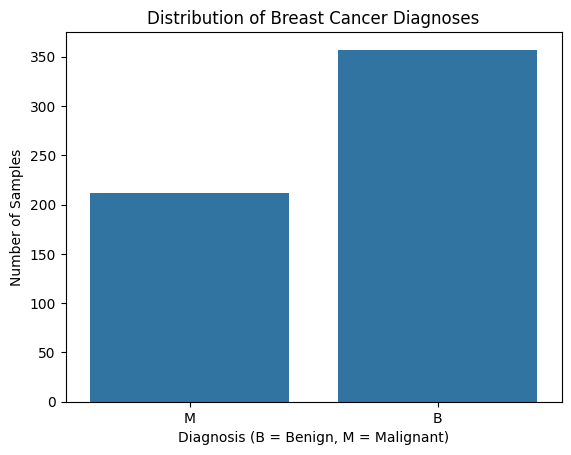

diagnosis
B    0.627
M    0.373
Name: proportion, dtype: float64


In [34]:
# now EDA
sns.countplot(data=df, x="diagnosis")
plt.title("Distribution of Breast Cancer Diagnoses")
plt.xlabel("Diagnosis (B = Benign, M = Malignant)")
plt.ylabel("Number of Samples")
plt.show()

print(df["diagnosis"].value_counts(normalize=True).round(3))

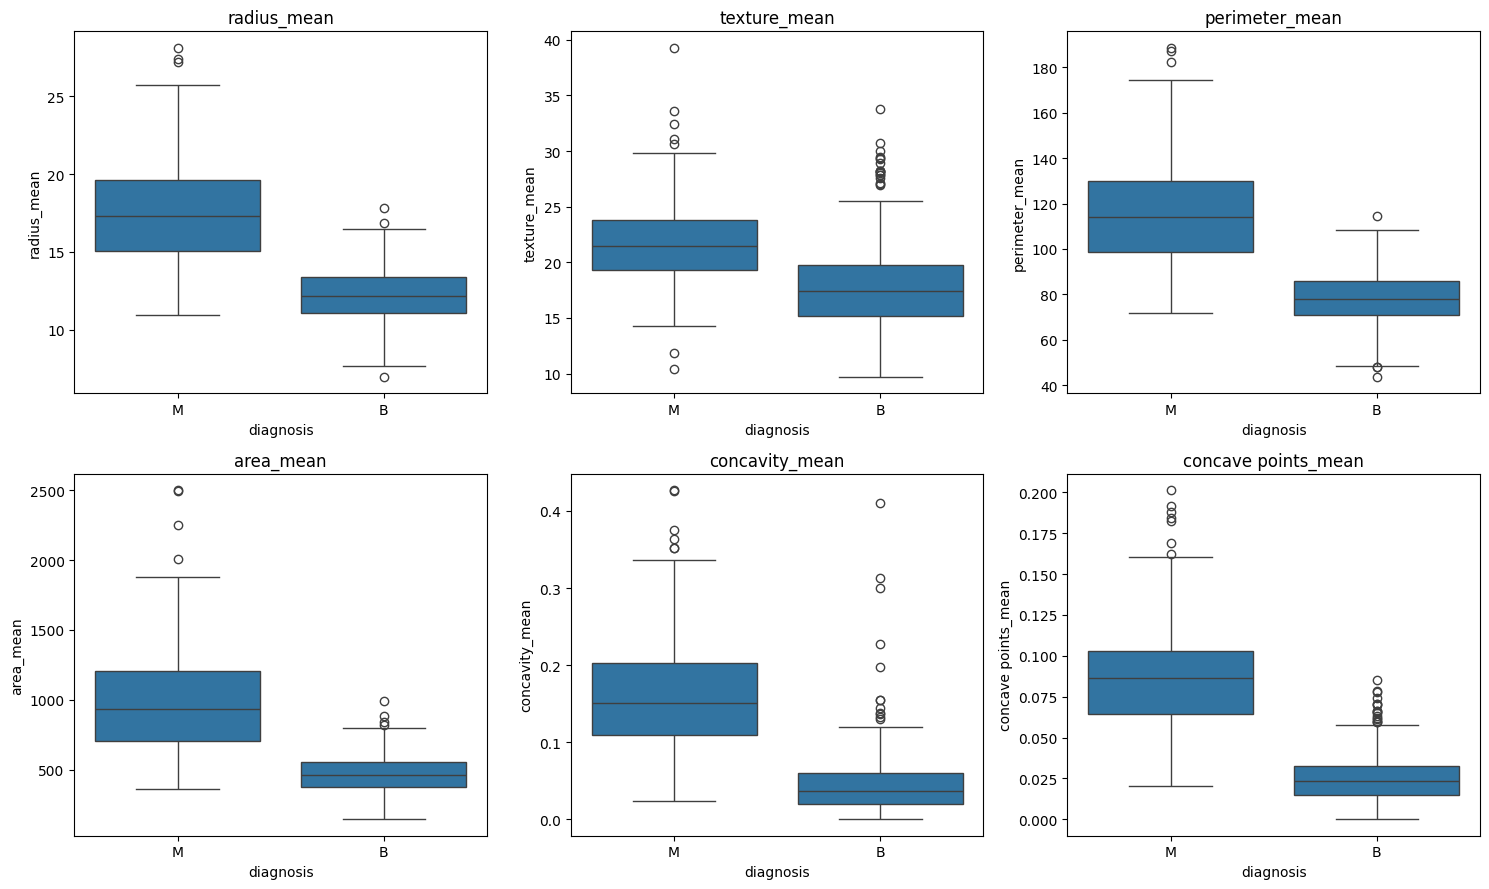

In [35]:
 # Separate features and target
features = [
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean",
    "concavity_mean",
    "concave points_mean"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for feature, ax in zip(features, axes.flatten()):
    sns.boxplot(data=df, x="diagnosis", y=feature, ax=ax)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

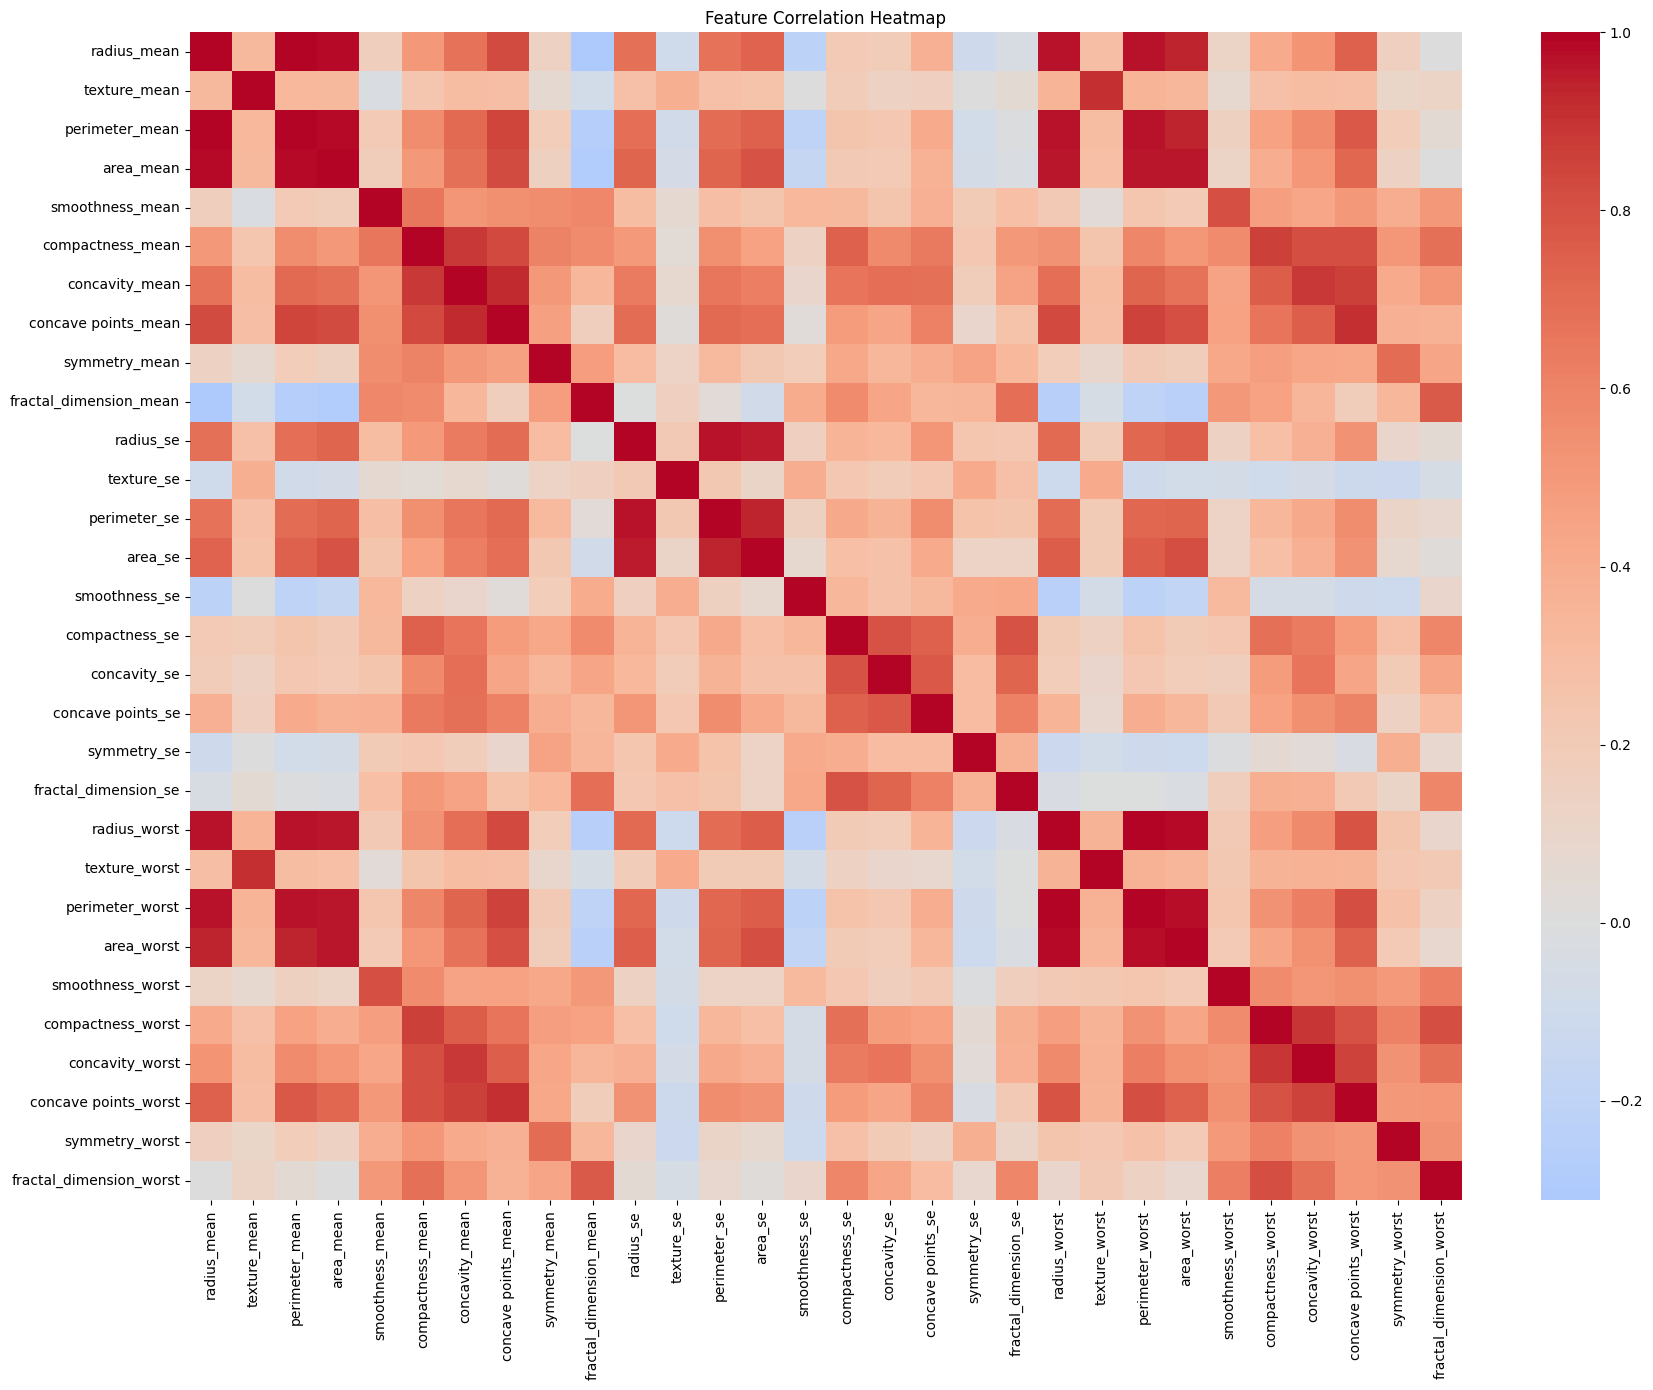

In [36]:
X_eda = df.drop(columns="diagnosis")
correlation = X_eda.corr()

plt.figure(figsize=(18, 14))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    xticklabels=True,
    yticklabels=True
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# We reserve 20% of the data as a final test set.
# stratify=y maintains approximately the same class proportions in both sets.

In [37]:
X = df.drop(columns="diagnosis")
y = df["diagnosis"].map({"B": 0, "M": 1})

print("Features:", X.shape)
print("Target:", y.shape)
print("Benign = 0, Malignant = 1")

Features: (569, 30)
Target: (569,)
Benign = 0, Malignant = 1


In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training samples: 455
Testing samples: 114

Training target distribution:
diagnosis
0    0.626
1    0.374
Name: proportion, dtype: float64

Testing target distribution:
diagnosis
0    0.632
1    0.368
Name: proportion, dtype: float64


In [39]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=400,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}
# We will compare:
# Logistic Regression
# Random Forest
# Support Vector Machine (SVM)

In [40]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Malignant Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    })

results_df = pd.DataFrame(results).sort_values(
    by="ROC-AUC",
    ascending=False
)

display(results_df.round(4))

# We will use pipelines so that missing-value
# imputation and scaling are fitted on the training data inside
# each cross-validation fold.
#

,Model,ROC-AUC,Accuracy,Precision,Malignant Recall,F1 Score,ROC-AUC Std
0,Logistic Regression,0.9958,0.9736,0.9771,0.9529,0.9640,0.0047
2,SVM,0.9948,0.9692,0.9646,0.9529,0.9583,0.0043
1,Random Forest,0.9889,0.9582,0.9470,0.9412,0.9438,0.0056


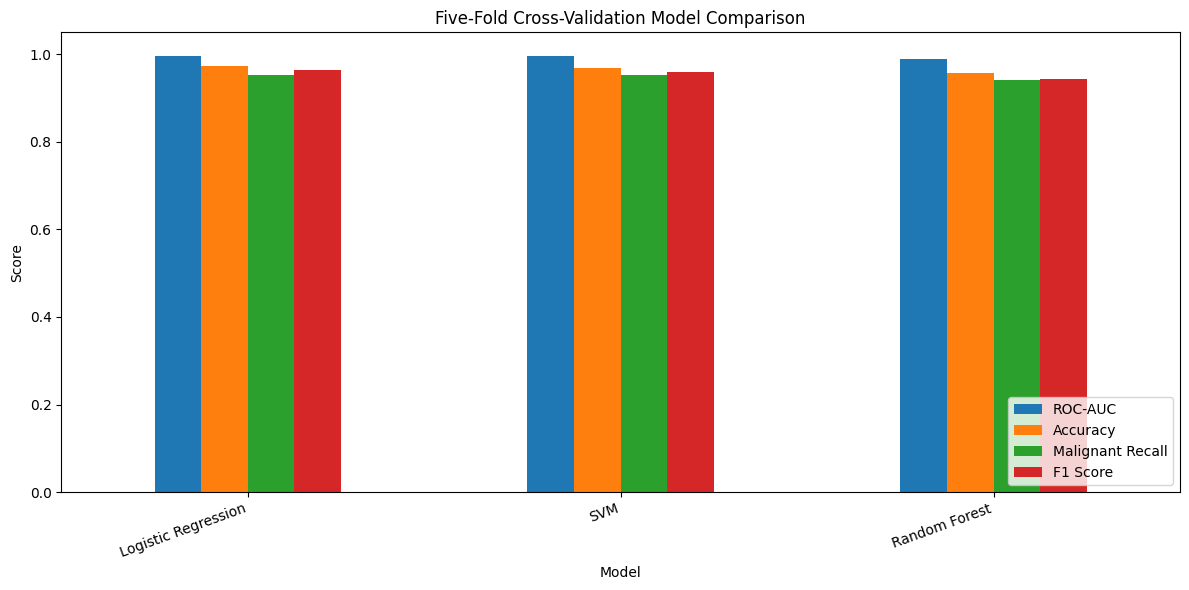

In [41]:
results_df.set_index("Model")[
    ["ROC-AUC", "Accuracy", "Malignant Recall", "F1 Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Five-Fold Cross-Validation Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [42]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

best_model.fit(X_train, y_train)

print("Selected model:", best_model_name)

Selected model: Logistic Regression


In [43]:
y_pred = best_model.predict(X_test)

# Probability of class 1 (malignant).
malignant_index = list(
    best_model.named_steps["model"].classes_
).index(1)

y_prob = best_model.predict_proba(X_test)[:, malignant_index]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Malignant recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

Accuracy: 0.9649
Precision: 0.975
Malignant recall: 0.9286
F1-score: 0.9512
ROC-AUC: 0.996

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



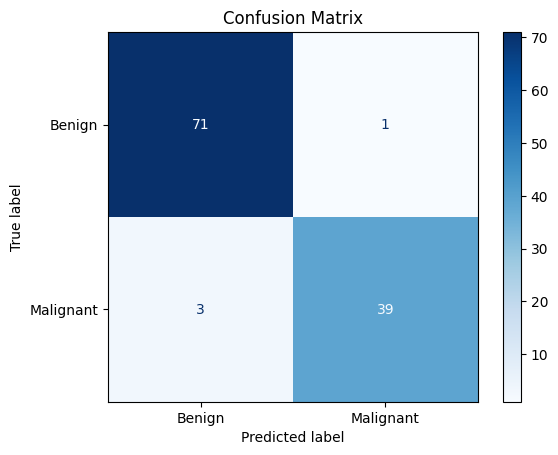

True negatives: 71
False positives: 1
False negatives: 3
True positives: 39


In [44]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

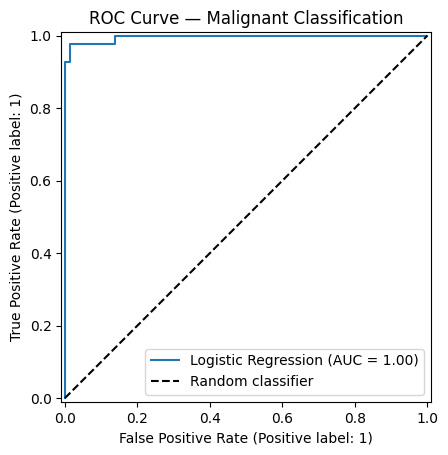

In [45]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name=best_model_name
)

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.title("ROC Curve — Malignant Classification")
plt.legend()
plt.show()

,Feature,Importance,Std
28,symmetry_worst,0.0098,0.0028
21,texture_worst,0.0088,0.0041
26,concavity_worst,0.0081,0.0030
7,concave points_mean,0.0038,0.0024
27,concave points_worst,0.0033,0.0016
6,concavity_mean,0.0030,0.0017
20,radius_worst,0.0027,0.0019
23,area_worst,0.0021,0.0015
22,perimeter_worst,0.0017,0.0014
11,texture_se,0.0016,0.0006


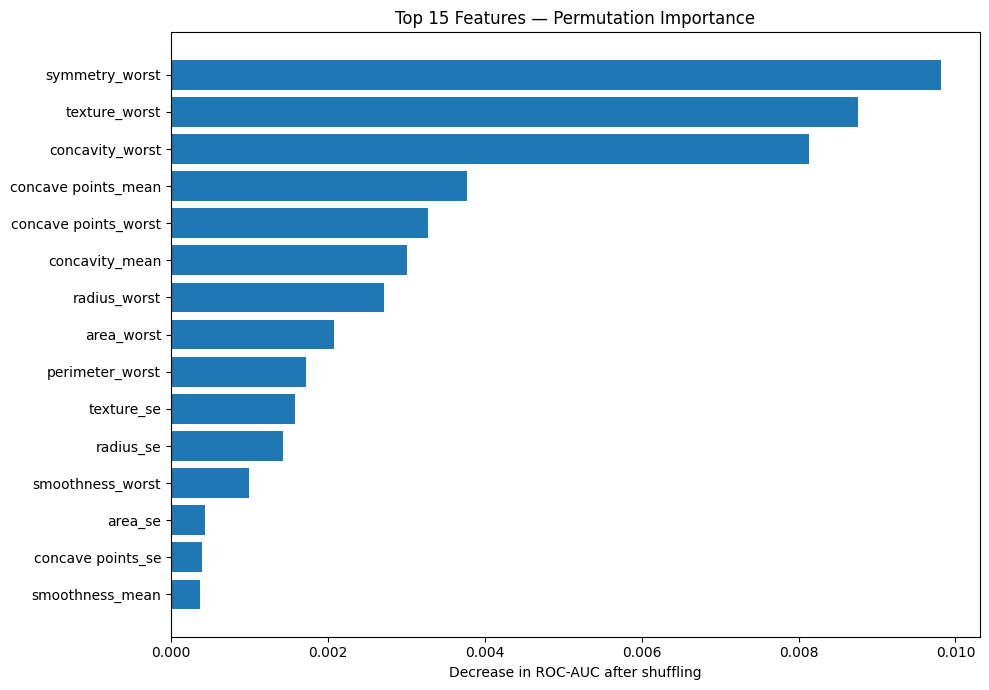

In [46]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Decrease in ROC-AUC after shuffling")
plt.title("Top 15 Features — Permutation Importance")
plt.tight_layout()
plt.show()

In [47]:
from sklearn.metrics import precision_score, recall_score

# Use probabilities from a validation set, not X_test.
# val_prob must be generated by a model fitted without val data.
# y_val must contain the corresponding validation labels.

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):
    pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "Malignant Recall": recall_score(
            y_val, pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))

,Threshold,Precision,Malignant Recall
0,0.10,0.768,1.000
1,0.15,0.808,0.977
2,0.20,0.840,0.977
3,0.25,0.857,0.977
4,0.30,0.913,0.977
5,0.35,0.955,0.977
6,0.40,0.955,0.977
7,0.45,0.955,0.977
8,0.50,0.955,0.977
9,0.55,0.955,0.977


In [48]:
import joblib
import json

joblib.dump(best_model, "breast_cancer_model.joblib")

metadata = {
    "model_name": best_model_name,
    "features": X.columns.tolist(),
    "target_mapping": {
        "0": "Benign",
        "1": "Malignant"
    },
    "default_threshold": 0.5,
    "intended_use": "Educational research only; not for clinical diagnosis"
}

with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Model and metadata saved.")

Model and metadata saved.


In [49]:
loaded_model = joblib.load("breast_cancer_model.joblib")

sample = X_test.iloc[[0]]
probability = loaded_model.predict_proba(sample)[0][malignant_index]

print("Estimated malignant probability:", round(float(probability), 4))

Estimated malignant probability: 0.0004


In [50]:
from google.colab import files

files.download("breast_cancer_model.joblib")
files.download("model_metadata.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>